In [2]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd

In [3]:
import pickle

In [19]:
### impacts calculated
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph2.pkl', 'rb') as file:
    imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/ed2.pkl', 'rb') as file:
    ed2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2.pkl', 'rb') as file:
    rd2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp2.pkl', 'rb') as file:
    impp2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd1_51ens.pkl', 'rb') as file:
    rd1_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp3.pkl', 'rb') as file:
#    impp3 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp5.pkl', 'rb') as file:
    impp5 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp6.pkl', 'rb') as file:
    impp6 = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp7.pkl', 'rb') as file:
#    impp7 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/exp_dict.pkl', 'rb') as file:
    exp_dict = pickle.load(file)

In [5]:
imph2

{'imph2_MOZ_new_FREDDY_20230306120000': <climada.engine.impact.Impact at 0x14e5d526c3d0>,
 'imph2_MOZ_new_FREDDY_20230307120000': <climada.engine.impact.Impact at 0x14e5d19d4510>,
 'imph2_MOZ_new_FREDDY_20230308120000': <climada.engine.impact.Impact at 0x14e5d19d45d0>,
 'imph2_MOZ_new_FREDDY_20230309120000': <climada.engine.impact.Impact at 0x14e5d19d4790>,
 'imph2_MOZ_new_FREDDY_20230310120000': <climada.engine.impact.Impact at 0x14e5d19d4a90>,
 'imph2_MOZ_new_FREDDY_20230311120000': <climada.engine.impact.Impact at 0x14e5d19d4e90>}

In [94]:
import numpy as np
import pandas as pd

summary_stats = []  # ✅ Reset before appending again
affected_counts_dict = {}

for lead_time_key, impact_obj in imph2.items():
    imp_dense_imph2 = impact_obj.imp_mat.toarray()
    affected_imph2 = imp_dense_imph2 > 0.20
    affected_counts_imph2 = affected_imph2.sum(axis=1)

    stats = {
        'lead_time': lead_time_key,
        'min_affected': int(np.min(affected_counts_imph2)),
        'median_affected': int(np.median(affected_counts_imph2)),
        'max_affected': int(np.max(affected_counts_imph2)),
        'mean_affected': round(np.mean(affected_counts_imph2)),
        'affected_array': affected_counts_imph2
    }
    summary_stats.append(stats)
    affected_counts_dict[lead_time_key] = affected_counts_imph2

summary_df = pd.DataFrame(summary_stats)
summary_df = summary_df.sort_values(by='lead_time')

In [95]:
# Define the mapping dictionary
rename_dict = {
    'imph2_MOZ_new_FREDDY_20230306120000': '5 days',
    'imph2_MOZ_new_FREDDY_20230307120000': '4 days',
    'imph2_MOZ_new_FREDDY_20230308120000': '3 days',
    'imph2_MOZ_new_FREDDY_20230309120000': '2 days',
    'imph2_MOZ_new_FREDDY_20230310120000': '1 day',
    'imph2_MOZ_new_FREDDY_20230311120000': 'landfall'
}

# Apply the mapping to the 'lead_time' column
summary_df['lead_time'] = summary_df['lead_time'].replace(rename_dict)

In [97]:
summary_df

,lead_time,min_affected,median_affected,max_affected,mean_affected,affected_array
0,5 days,0,84,275,97,"[0, 17, 0, 101, 250, 206, 5, 0, 1, 23, 197, 19..."
1,4 days,0,69,262,77,"[90, 0, 0, 0, 27, 2, 0, 138, 19, 14, 10, 108, ..."
2,3 days,0,43,236,57,"[165, 127, 4, 81, 84, 77, 95, 32, 62, 0, 0, 29..."
3,2 days,64,124,346,136,"[115, 140, 75, 82, 187, 119, 110, 154, 104, 17..."
4,1 day,77,146,282,153,"[222, 119, 123, 77, 122, 133, 106, 188, 236, 1..."
5,landfall,52,122,230,129,"[169, 157, 178, 122, 163, 133, 130, 93, 112, 1..."


In [99]:
# Create a new dictionary with renamed keys using the same rename_dict
affected_counts_dict = {
    rename_dict.get(key, key): value for key, value in affected_counts_dict.items()
}

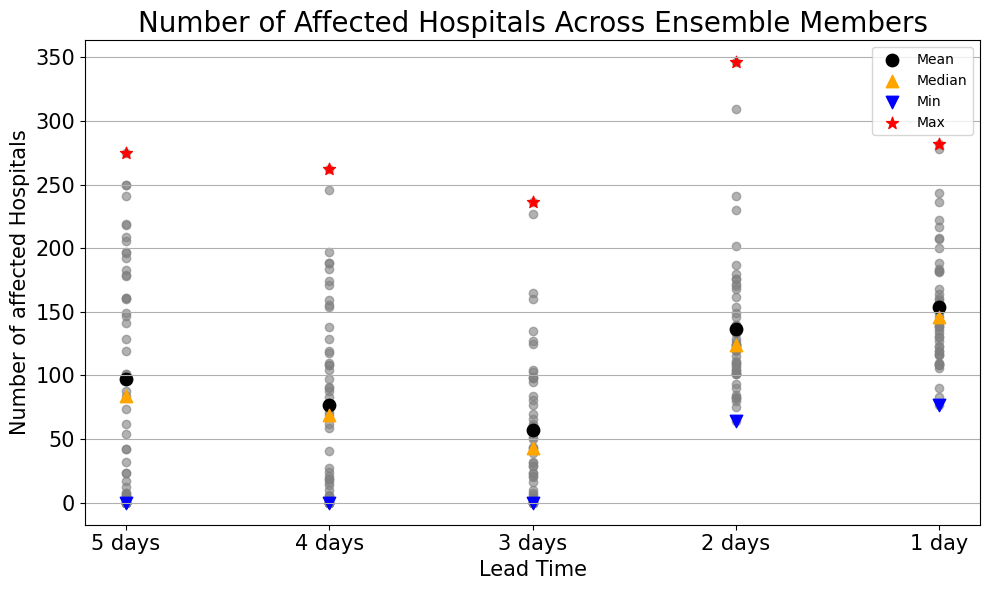

In [157]:
import matplotlib.pyplot as plt
import numpy as np

# Data preparation
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict[lt] for lt in lead_times]

plt.figure(figsize=(10, 6))

# Plot all points
for i, (lt, values) in enumerate(zip(lead_times, dot_data)):
    x = np.full_like(values, i + 1)  # Position on x-axis
    # Basic points
    plt.scatter(x, values, color='gray', alpha=0.6, label='_nolegend_')

    # Highlight statistics
    mean = np.mean(values)
    median = np.median(values)
    min_val = np.min(values)
    max_val = np.max(values)

    plt.scatter(i + 1, mean, color='black', s=80, marker='o', label='Mean' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, median, color='orange', s=80, marker='^', label='Median' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, min_val, color='blue', s=80, marker='v', label='Min' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, max_val, color='red', s=80, marker='*', label='Max' if i == 0 else "_nolegend_")

# Aesthetics
plt.xticks(ticks=range(1, len(lead_times) + 1), labels=lead_times, fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel("Lead Time", fontsize=15)
plt.ylabel("Number of affected Hospitals", fontsize=15)
plt.title("Number of Affected Hospitals Across Ensemble Members", fontsize=20)
plt.grid(axis='y')
plt.legend()
# ✅ Save the figure
plt.tight_layout()
plt.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/affected_hospitals_by_lead_time.png", dpi=600)  # High resolution PNG
plt.show()

In [ ]:
###For schools 

In [114]:
import numpy as np
import pandas as pd

summary_stats_ed2 = []
affected_counts_dict_ed2 = {}

for lead_time_key, impact_obj in ed2.items():
    imp_dense_ed2 = impact_obj.imp_mat.toarray()
    affected_ed2 = imp_dense_ed2 > 0.20
    affected_counts_ed2 = affected_ed2.sum(axis=1)

    stats = {
        'lead_time': lead_time_key,
        'min_affected': int(np.min(affected_counts_ed2)),
        'median_affected': int(np.median(affected_counts_ed2)),
        'max_affected': int(np.max(affected_counts_ed2)),
        'mean_affected': round(np.mean(affected_counts_ed2)),
        'affected_array': affected_counts_ed2
    }
    summary_stats_ed2.append(stats)
    affected_counts_dict_ed2[lead_time_key] = affected_counts_ed2

summary_df_ed2 = pd.DataFrame(summary_stats_ed2)
summary_df_ed2 = summary_df_ed2.sort_values(by='lead_time')

In [117]:
# Define the mapping dictionary
rename_dict = {
    'ed2_MOZ_new_FREDDY_20230306120000': '5 days',
    'ed2_MOZ_new_FREDDY_20230307120000': '4 days',
    'ed2_MOZ_new_FREDDY_20230308120000': '3 days',
    'ed2_MOZ_new_FREDDY_20230309120000': '2 days',
    'ed2_MOZ_new_FREDDY_20230310120000': '1 day',
    'ed2_MOZ_new_FREDDY_20230311120000': 'landfall'
}

# Apply the mapping to the 'lead_time' column
summary_df_ed2['lead_time'] = summary_df_ed2['lead_time'].replace(rename_dict)

In [118]:
summary_df_ed2

,lead_time,min_affected,median_affected,max_affected,mean_affected,affected_array
0,5 days,0,23,141,29,"[0, 44, 0, 15, 50, 48, 1, 0, 0, 2, 37, 36, 49,..."
1,4 days,0,17,120,22,"[31, 0, 0, 1, 58, 0, 0, 31, 18, 6, 8, 18, 23, ..."
2,3 days,0,10,60,16,"[43, 31, 0, 12, 28, 10, 18, 58, 9, 0, 0, 5, 2,..."
3,2 days,11,29,121,37,"[24, 34, 11, 14, 88, 28, 56, 31, 23, 119, 15, ..."
4,1 day,15,37,153,59,"[136, 18, 28, 15, 38, 32, 19, 116, 136, 35, 83..."
5,landfall,10,27,124,33,"[59, 61, 123, 23, 38, 31, 27, 15, 16, 19, 26, ..."


In [120]:
# Create a new dictionary with renamed keys using the same rename_dict
affected_counts_dict_ed2 = {
    rename_dict.get(key, key): value for key, value in affected_counts_dict_ed2.items()
}

In [ ]:
###plotting schools 

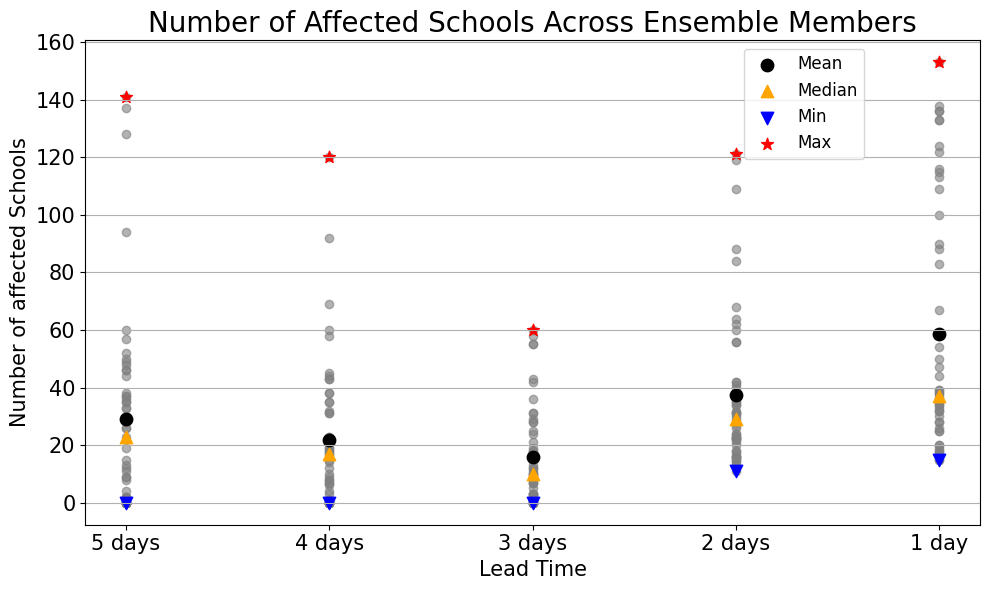

In [158]:
import matplotlib.pyplot as plt
import numpy as np

# Data preparation
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict_ed2[lt] for lt in lead_times]

plt.figure(figsize=(10, 6))

# Plot all points
for i, (lt, values) in enumerate(zip(lead_times, dot_data)):
    x = np.full_like(values, i + 1)  # Position on x-axis
    # Basic points
    plt.scatter(x, values, color='gray', alpha=0.6, label='_nolegend_')

    # Highlight statistics
    mean = np.mean(values)
    median = np.median(values)
    min_val = np.min(values)
    max_val = np.max(values)

    plt.scatter(i + 1, mean, color='black', s=80, marker='o', label='Mean' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, median, color='orange', s=80, marker='^', label='Median' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, min_val, color='blue', s=80, marker='v', label='Min' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, max_val, color='red', s=80, marker='*', label='Max' if i == 0 else "_nolegend_")

# Aesthetics
plt.xticks(ticks=range(1, len(lead_times) + 1), labels=lead_times, fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel("Lead Time", fontsize=15)
plt.ylabel("Number of affected Schools", fontsize=15)
plt.title("Number of Affected Schools Across Ensemble Members", fontsize=20)
plt.grid(axis='y')
#plt.legend(loc='upper right', fontsize=12)
plt.legend(loc='upper right', bbox_to_anchor=(0.88, 1), fontsize=12)
# ✅ Save the figure
plt.tight_layout()
plt.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/affected_schools_by_lead_time.png", dpi=600)  # High resolution PNG
plt.show()

In [130]:
###roads
def join_road_exp_51ens(ens_51, exposure_gdf):
    results = {}
    for key, df in ens_51.items():
        df = df.reset_index(drop=True)
        exposure_gdf = exposure_gdf.reset_index(drop=True)

        if len(df) == len(exposure_gdf):
            df['osm_id'] = exposure_gdf['osm_id']
        else:
            raise ValueError(f"Mismatch in DataFrame lengths for key: {key}")

        grouped = df.groupby('osm_id').mean()
        first_geometry = exposure_gdf.drop_duplicates(subset=['osm_id'])[['osm_id', 'geometry_orig']]
        merged_grouped = grouped.merge(first_geometry, on='osm_id', how='left')

        column_range = list(range(51))
        merged_grouped['mean_impact'] = merged_grouped[column_range].mean(axis=1)

        # Keep all ensemble columns, 'mean_impact', and 'geometry_orig'
        ensemble_cols = [col for col in merged_grouped.columns if isinstance(col, int) or col == 'mean_impact']
        final_cols = ['osm_id'] + ensemble_cols + ['geometry_orig']
        final_result = merged_grouped[final_cols]

        geo_df = gpd.GeoDataFrame(final_result, geometry='geometry_orig')
        geo_df.set_crs(epsg=4326, inplace=True)

        results[key] = geo_df

    return results

In [131]:
rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_dict['exp_rd2_MOZ'].gdf)
rd2_mimpact

{'20230306120000':             osm_id          0    1    2           3           4           5  \
 0       1000094235   0.000000  0.0  0.0    0.000000    0.000000    0.000000   
 1       1000094236   0.000000  0.0  0.0    0.000000    0.000000    0.000000   
 2       1000094237   0.000000  0.0  0.0    0.000000    0.000000    0.000000   
 3       1000094238   0.000000  0.0  0.0    0.000000    0.000000    0.000000   
 4       1000094239   0.000000  0.0  0.0    0.000000    0.000000    0.000000   
 ...            ...        ...  ...  ...         ...         ...         ...   
 267272   999858614  12.009117  0.0  0.0  109.956948  194.025008  172.497868   
 267273   999859262  12.009117  0.0  0.0  109.956948  194.025008  172.497868   
 267274   999860028  12.009117  0.0  0.0  109.956948  194.025008  172.497868   
 267275   999865566  12.009117  0.0  0.0  109.956948  194.025008  172.497868   
 267276   999866041  12.490354  0.0  0.0   61.650939  192.658654  169.050536   
 
           6    7   

In [132]:
### scale 
def mimpact_cols_scale(data_dict, divisor):
    """
    Scales columns 0 to 50 and 'mean_impact' in all DataFrames within a dictionary.

    Parameters:
    data_dict (dict): Dictionary containing the DataFrames.
    divisor (int or float): Value by which to divide the column values.

    Returns:
    None; the operation modifies the DataFrames in place.
    """
    for key, df in data_dict.items():
        # Select columns that are integers from 0 to 50 or 'mean_impact'
        cols_to_scale = [col for col in df.columns if 
                         (isinstance(col, int) and 0 <= col <= 50) or col == 'mean_impact']
        
        # Only scale if those columns are present
        if cols_to_scale:
            df[cols_to_scale] = df[cols_to_scale] / divisor
        else:
            print(f"No matching columns found in DataFrame for key '{key}'.")

In [133]:
mimpact_cols_scale(rd2_mimpact, 500.0)

In [135]:
# Your rename_dict
rename_dict = {
    '20230306120000': '5 days',
    '20230307120000': '4 days',
    '20230308120000': '3 days',
    '20230309120000': '2 days',
    '20230310120000': '1 day',
    '20230311120000': 'landfall'
}

# Create a new dictionary with renamed keys
rd2_mimpact= {
    rename_dict.get(k, k): v for k, v in rd2_mimpact.items()
}

In [151]:
import numpy as np
import pandas as pd

# Initialize list to collect summary stats per lead time
summary_stats_rd2 = []

# Loop through each key (lead time) and its GeoDataFrame
for lead_time_key, gdf in rd2_mimpact.items():
    # Select ensemble member columns (0 to 50)
    ens_cols = [col for col in gdf.columns if isinstance(col, int) and 0 <= col <= 50]
    
    # Convert the ensemble columns to a NumPy array
    impact_array = gdf[ens_cols].values  # Shape: (n_roads, 51)

    # Identify affected roads per ensemble (impact ≥ 0.20)
    affected = impact_array >= 0.20

    # Count affected roads for each ensemble member
    affected_counts = affected.sum(axis=0)  # Shape: (51,)

    # Compute statistics
    stats = {
        'lead_time': lead_time_key,
        'min_affected': int(np.min(affected_counts)),
        'median_affected': int(np.median(affected_counts)),
        'max_affected': int(np.max(affected_counts)),
        'mean_affected': round(np.mean(affected_counts))
    }
    summary_stats_rd2.append(stats)

# Create DataFrame
summary_df_rd2 = pd.DataFrame(summary_stats_rd2)

# ✅ Define custom lead time order
lead_time_order = ['5 days', '4 days', '3 days', '2 days', '1 day', 'landfall']

# ✅ Apply custom order using pandas Categorical
summary_df_rd2['lead_time'] = pd.Categorical(summary_df_rd2['lead_time'], categories=lead_time_order, ordered=True)

# ✅ Sort by the ordered lead_time
summary_df_rd2 = summary_df_rd2.sort_values(by='lead_time')

# ✅ Display result
summary_df_rd2

,lead_time,min_affected,median_affected,max_affected,mean_affected
0,5 days,0,17525,98543,26068
1,4 days,0,13130,63949,21048
2,3 days,0,10032,73413,16379
3,2 days,9472,30770,73935,35879
4,1 day,10116,45435,98927,47816
5,landfall,7132,35734,78768,37252


In [152]:
affected_counts_dict_rd2

{'5 days': array([    0,  9953,     0, 23393, 55241, 70483,   378,     0,    58,
         3737, 51669, 50730, 61856, 84115,  1059,  8909,     0,  1756,
        49385,  7707,     0,  6280, 48916,  5692,  2494, 98543, 86845,
        17525,     0,  1765,  3389, 47967,     0, 52670, 59485, 15132,
        48362, 23039, 21776, 35121,  1276,  1120, 33463, 61748, 44363,
        18810, 29813,   152,     0, 44984, 38294]),
 '4 days': array([39884,     7,     0,   162, 13130,   123,     0, 45632, 10229,
         3305, 10650, 21302, 30435,  1793,  5076, 36628,     0, 53490,
        25695, 26788,  9723, 24614,  3394,  2375,   503,     4, 24150,
        58098, 63949,     0, 47341, 32706, 43225,  2394,     0, 49793,
        48587,  9686,   411, 13000, 16324, 46900, 10491, 32480,    85,
        17373,  1787, 62493, 47174, 49493, 30581]),
 '3 days': array([49491, 48055,   298, 17613, 34550, 12616, 25171, 24800,  9624,
            1,   146,  3671,   215, 33948,   320,  4032, 23784, 56479,
         3572,

In [ ]:
###plotting roads affected 

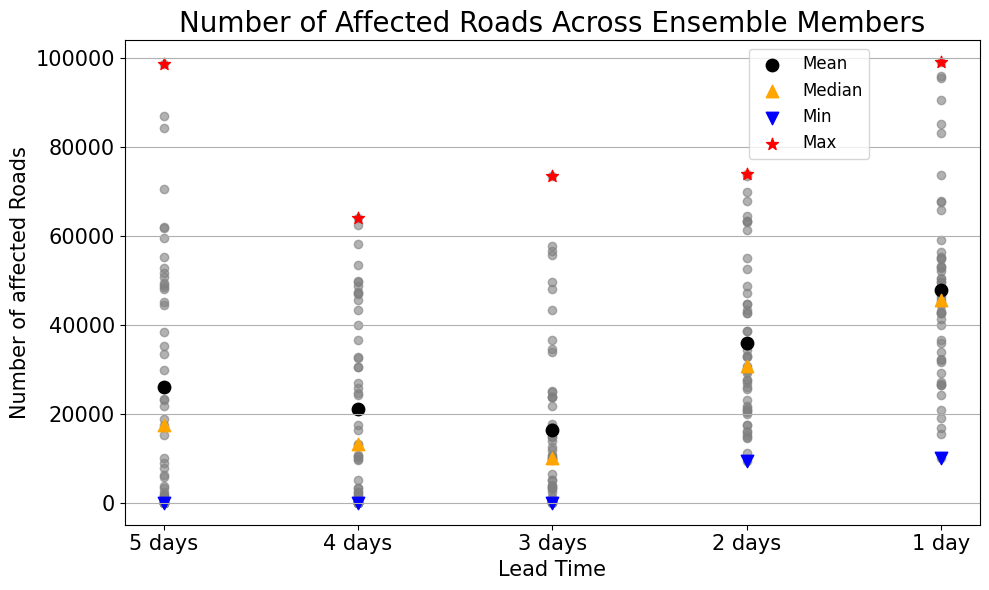

In [159]:
import matplotlib.pyplot as plt
import numpy as np

# Data preparation
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict_rd2[lt] for lt in lead_times]

plt.figure(figsize=(10, 6))

# Plot all points
for i, (lt, values) in enumerate(zip(lead_times, dot_data)):
    x = np.full_like(values, i + 1)  # Position on x-axis
    # Basic points
    plt.scatter(x, values, color='gray', alpha=0.6, label='_nolegend_')

    # Highlight statistics
    mean = np.mean(values)
    median = np.median(values)
    min_val = np.min(values)
    max_val = np.max(values)

    plt.scatter(i + 1, mean, color='black', s=80, marker='o', label='Mean' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, median, color='orange', s=80, marker='^', label='Median' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, min_val, color='blue', s=80, marker='v', label='Min' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, max_val, color='red', s=80, marker='*', label='Max' if i == 0 else "_nolegend_")

# Aesthetics
plt.xticks(ticks=range(1, len(lead_times) + 1), labels=lead_times, fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel("Lead Time", fontsize=15)
plt.ylabel("Number of affected Roads", fontsize=15)
plt.title("Number of Affected Roads Across Ensemble Members", fontsize=20)
plt.grid(axis='y')
#plt.legend(loc='upper right', fontsize=12)
plt.legend(loc='upper right', bbox_to_anchor=(0.88, 1), fontsize=12)
# ✅ Save the figure
plt.tight_layout()
plt.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/affected_roads_by_lead_time.png", dpi=600)  # High resolution PNG
plt.show()

In [153]:
# Define the mapping dictionary
rename_dict = {
    '20230306120000': '5 days',
    '20230307120000': '4 days',
    '20230308120000': '3 days',
    '20230309120000': '2 days',
    '20230310120000': '1 day',
    '20230311120000': 'landfall'
}

# Apply the mapping to the 'lead_time' column
summary_df_rd2['lead_time'] = summary_df_rd2['lead_time'].replace(rename_dict)

In [154]:
summary_df_rd2

,lead_time,min_affected,median_affected,max_affected,mean_affected
0,5 days,0,17525,98543,26068
1,4 days,0,13130,63949,21048
2,3 days,0,10032,73413,16379
3,2 days,9472,30770,73935,35879
4,1 day,10116,45435,98927,47816
5,landfall,7132,35734,78768,37252
